In [127]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
  "font.size": 9,
  "axes.titlesize": 9,
  "axes.labelsize": 9,
  "xtick.labelsize": 9,
  "ytick.labelsize": 9,
  "legend.fontsize": 9
})

In [128]:
def read_spike_times(cell_id):
  spike_times = pd.read_csv(
    f"../output/temporal-interference-1/{cell_id}/random_poisson/5/1000_5_0.5_0.1/synapse_stimuli.csv",
    header = None
  )
  spike_times = spike_times.fillna('').values.tolist()
  spike_times = [[x / 1000 for x in row if x != ""] for row in spike_times]

  return spike_times

In [138]:
cell_id = 10

filename = f"../output/temporal-interference-1/{cell_id}/random_poisson/5/noTI_0.1/voltage.csv"
voltage = pd.read_csv(filename, index_col = 0)

filename = f"../output/temporal-interference-1/{cell_id}/random_poisson/5/noTI_0.1/synapse_weights.csv"
synapse_weights = pd.read_csv(filename, index_col = 0)

filename = f"../output/temporal-interference-1/{cell_id}/random_poisson/5/1000_5_0.5_0.1/voltage.csv"
voltage_50 = pd.read_csv(filename, index_col = 0)

filename = f"../output/temporal-interference-1/{cell_id}/random_poisson/5/1000_5_0.5_0.1/synapse_weights.csv"
synapse_weights_50 = pd.read_csv(filename, index_col = 0)

filename = f"../output/temporal-interference-1/{cell_id}/random_poisson/5/1000_5_0.9_0.1/voltage.csv"
voltage_90 = pd.read_csv(filename, index_col = 0)

filename = f"../output/temporal-interference-1/{cell_id}/random_poisson/5/1000_5_0.9_0.1/synapse_weights.csv"
synapse_weights_90 = pd.read_csv(filename, index_col = 0)

filename = f"../output/temporal-interference-1/{cell_id}/random_poisson/5/1000_5_0.5_0.1/synapse_stimuli.csv"
stimuli = read_spike_times(cell_id)

colors = {
  "No tTIS": "#0D0887",
  "50% tTIS": "#E16462",
  "90% tTIS": "#B12A90"
}

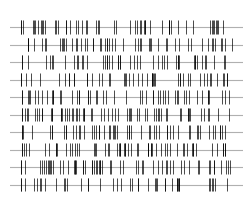

In [139]:
fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (3, 2.5))

for i, spikes in enumerate(stimuli):
  ax.eventplot(spikes, lineoffsets = i + 1, linelengths = 0.75, colors = "black", linewidths = 0.5)

ax.set_ylim(0, 11)
ax.set_yticks(np.arange(1, 11, 1))
ax.set_yticklabels([])

ax.set_xlabel("")

ax.xaxis.grid(False)
ax.yaxis.grid(True)

ax.tick_params(left = None, bottom = None, labelbottom = None)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)



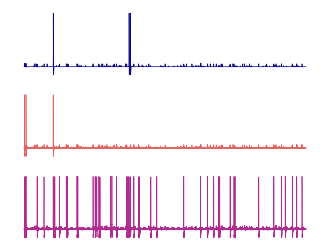

In [140]:
fig, axs = plt.subplots(nrows = 3, ncols = 1, figsize = (4, 3))

axs[0].plot(voltage.Time / 1000, voltage.Voltage, linewidth = 0.5, color = colors["No tTIS"])
axs[1].plot(voltage_50.Time / 1000, voltage_50.Voltage, linewidth = 0.5, color = colors["50% tTIS"])
axs[2].plot(voltage_90.Time / 1000, voltage_90.Voltage, linewidth = 0.5, color = colors["90% tTIS"])

for ax in axs:
  ax.spines["top"].set_visible(False)
  ax.spines["right"].set_visible(False)
  ax.spines["bottom"].set_visible(False)
  ax.spines["left"].set_visible(False)

  ax.tick_params(left = None, labelleft = None, bottom = None, labelbottom = None)

Text(0, 0.5, '$\\Delta w$')

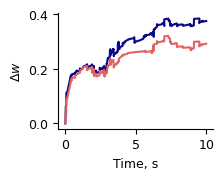

In [142]:
fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (2, 1.5), sharey = True)
ax = axs

for weights, stimulation in zip(
  [synapse_weights, synapse_weights_50],
  ["No tTIS", "50% tTIS"]
):
  synapses = [ f"Synapse{id}" for id in range(0, 10) ]
  mean = np.abs(weights[synapses] - 0.1).mean(axis = 1)
  ax.plot(weights.Time / 1000, mean, color = colors[stimulation])

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlabel("Time, s")
ax.set_ylabel(rf"$\Delta w$")
